# MLP from Scratch Demo

## Purpose

Acquire basic knowledge for defining and training MLPs from scratch.

In [27]:
# 1. Data Pipeline
import numpy as np
import pandas as pd

# Experiment data resides in data/student.csv
df = pd.read_csv("../data/student.csv")

y = df["Exam_Score"]
X = df.drop(columns=["Exam_Score"])

# Categorial encoding
cat = X.select_dtypes(include="str")
num = X.select_dtypes(include="int64").astype(np.float32)
X_enc = pd.get_dummies(cat)
X = np.concatenate([num.values, X_enc.values], axis=1)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalize using TRAIN stats only
mu = X_train.mean(0)
std = X_train.std(0) + 1e-8

X_train = (X_train - mu) / std
X_test  = (X_test  - mu) / std

y_mu = y_train.mean()
y_std = y_train.std() + 1e-8

y_train = (y_train - y_mu) / y_std
y_test  = (y_test  - y_mu) / y_std

# reshape
y_train = y_train.values.reshape(-1,1)
y_test  = y_test.values.reshape(-1,1)

In [41]:
# 2. MLP Definition
import matplotlib.pyplot as plt

dims = [X_train.shape[1], 63, 32, 1]

W1 = np.random.randn(dims[0], dims[1]) * np.sqrt(2.0 / dims[0])
b1 = np.zeros((1, dims[1]))

W2 = np.random.randn(dims[1], dims[2]) * np.sqrt(2.0 / dims[1])
b2 = np.zeros((1, dims[2]))

W3 = np.random.randn(dims[2], dims[3]) * np.sqrt(2.0 / dims[2])
b3 = np.zeros((1, dims[3]))

epochs = 500
lr = 1e-3
batch_size = 64

train_losses = []
val_losses = []

def mse(y_hat, y):
    return np.mean((y_hat - y) ** 2)

def relu(x):
    return np.maximum(0, x)

def relu_grad(x):
    return (x > 0).astype(np.float32)

N = X_train.shape[0]

for epoch in range(epochs):

    # ---- shuffle ----
    idx = np.random.permutation(N)
    Xs = X_train[idx]
    ys = y_train[idx]

    epoch_loss = 0

    # ---- mini-batch ----
    for i in range(0, N, batch_size):
        Xb = Xs[i:i+batch_size]
        yb = ys[i:i+batch_size]

        # ---- forward ----
        z1 = Xb @ W1 + b1
        a1 = relu(z1)

        z2 = a1 @ W2 + b2
        a2 = relu(z2)

        z3 = a2 @ W3 + b3
        y_hat = z3

        # ---- loss ----
        loss = mse(y_hat, yb)
        epoch_loss += loss

        # ---- backward ----
        Nb = yb.shape[0]
        dz3 = 2*(y_hat - yb)/Nb

        dW3 = a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        da2 = dz3 @ W3.T
        dz2 = da2 * relu_grad(z2)
        dW2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ W2.T
        dz1 = da1 * relu_grad(z1)
        dW1 = Xb.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # ---- update ----
        W3 -= lr * dW3
        b3 -= lr * db3
        W2 -= lr * dW2
        b2 -= lr * db2
        W1 -= lr * dW1
        b1 -= lr * db1

    # ---- epoch metrics ----
    z1f = X_train @ W1 + b1
    a1f = relu(z1f)
    z2f = a1f @ W2 + b2
    a2f = relu(z2f)
    z3f = a2f @ W3 + b3
    y_hat_f = z3f
    train_loss = mse(y_hat_f, y_train)

    train_losses.append(train_loss)

    # ---- validation ----
    z1v = X_test @ W1 + b1
    a1v = relu(z1v)

    z2v = a1v @ W2 + b2
    a2v = relu(z2v)

    z3v = a2v @ W3 + b3
    yv_hat = z3v

    val_loss = mse(yv_hat, y_test)
    val_losses.append(val_loss)

    if epoch % 50 == 0:
        print(f"epoch {epoch} | train MSE: {train_loss:.4f} | val MSE: {val_loss:.4f}")


epoch 0 | train MSE: 1.5010 | val MSE: 1.5406
epoch 50 | train MSE: 0.3791 | val MSE: 0.3208
epoch 100 | train MSE: 0.3288 | val MSE: 0.2789
epoch 150 | train MSE: 0.3066 | val MSE: 0.2626
epoch 200 | train MSE: 0.2936 | val MSE: 0.2546
epoch 250 | train MSE: 0.2850 | val MSE: 0.2509
epoch 300 | train MSE: 0.2788 | val MSE: 0.2495
epoch 350 | train MSE: 0.2735 | val MSE: 0.2481
epoch 400 | train MSE: 0.2690 | val MSE: 0.2478
epoch 450 | train MSE: 0.2651 | val MSE: 0.2479


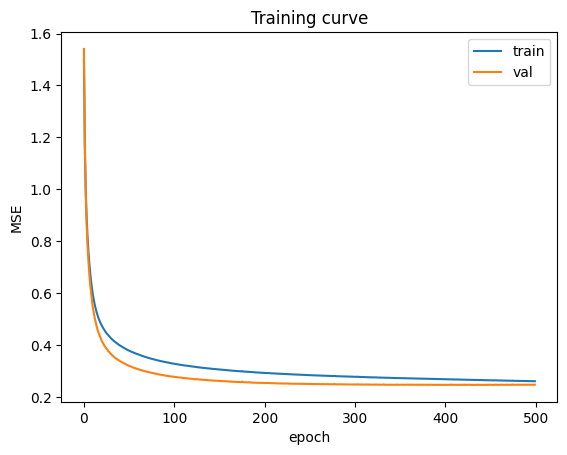

0.26172099147452205 0.2482427066106824


In [42]:
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.legend()
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Training curve")
plt.show()
print(train_losses[-1], val_losses[-1])

